# Exploración de tallas de cometa

Este notebook analiza **un único escenario meteorológico cada vez**, como hará el frontend. Permite comprobar la fórmula actual, inspeccionar tallas candidatas y detectar cuándo el resultado está limitado por el rango visible.

## Alcance y límites

- Supuesto base: kitesurf freeride con twin-tip y cometa LEI convencional.
- Fórmula inicial: `talla ideal (m²) = peso (kg) × 2.2 / viento medio (nudos)`.
- El mapa muestra una **puntuación relativa a esa fórmula**, no una probabilidad ni una evaluación de si las condiciones son aptas para navegar.
- El viento medio se utiliza como base. Las rachas se muestran como contexto, pero no se les aplica un multiplicador inventado sin datos que lo validen.
- La fórmula y la tolerancia deben contrastarse con la tabla de viento del modelo concreto de cometa. Las marcas publican rangos distintos por modelo y estilo.

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Ajusta estos valores para explorar el pronóstico horario seleccionado.
WIND_MEAN_KMH = 18.0
WIND_GUSTS_KMH = 23.0  # usa None si no hay dato de rachas

WEIGHT_MIN_KG = 40
WEIGHT_MAX_KG = 120
WEIGHT_STEP_KG = 5
KITE_SIZE_MIN_M2 = 4
KITE_SIZE_MAX_M2 = 21

# Tolerancia relativa provisional, heredada del servicio actual.
SIZE_TOLERANCE_RATIO = 0.25

weights_kg = np.arange(WEIGHT_MIN_KG, WEIGHT_MAX_KG + 1, WEIGHT_STEP_KG)
kite_sizes_m2 = np.arange(KITE_SIZE_MIN_M2, KITE_SIZE_MAX_M2 + 1)

assert len(weights_kg) == 17
assert len(kite_sizes_m2) == 18
assert len(weights_kg) * len(kite_sizes_m2) == 306

## 1. Fórmula y función de puntuación

La fórmula `peso × 2.2 / viento` es una regla práctica muy difundida, no una ley física exacta ni un estándar universal. Las fuentes consultadas recomiendan considerar además el tipo de tabla, nivel, estilo, cometa y condiciones; los rangos publicados por fabricantes son específicos de cada modelo.

Por ahora mantenemos la función de puntuación que usa el backend para no crear una segunda implementación divergente. Ejecuta el notebook desde `backend/` para que el import encuentre el paquete.

In [12]:
from kite_forecast.services.kite_sizing import _suitability_score


def ideal_kite_size(weight_kg: float, wind_kmh: float) -> float:
    """Estimación inicial para freeride/twin-tip; no es una recomendación validada."""
    if wind_kmh <= 0:
        return float("nan")
    return weight_kg * 2.2 / wind_kmh


def build_scores(wind_kmh: float) -> np.ndarray:
    """Matriz [talla, peso], reutilizando la puntuación del servicio backend."""
    scores = np.zeros((len(kite_sizes_m2), len(weights_kg)), dtype=float)
    if wind_kmh <= 0:
        return scores

    for col, weight in enumerate(weights_kg):
        ideal_size = ideal_kite_size(float(weight), wind_kmh)
        for row, size in enumerate(kite_sizes_m2):
            scores[row, col] = _suitability_score(int(size), ideal_size)
    return scores


print(f"Viento medio: {WIND_MEAN_KMH:.1f} kmh")
if WIND_GUSTS_KMH is not None:
    print(f"Rachas: {WIND_GUSTS_KMH:.1f} kmh")
    print(f"Diferencia racha-media: {WIND_GUSTS_KMH - WIND_MEAN_KMH:.1f} kmh")
print(
    f"Matriz: {len(weights_kg)} pesos × {len(kite_sizes_m2)} tallas = {len(weights_kg) * len(kite_sizes_m2)} celdas"
)

Viento medio: 18.0 kmh
Rachas: 23.0 kmh
Diferencia racha-media: 5.0 kmh
Matriz: 17 pesos × 18 tallas = 306 celdas


## 2. Un único mapa de calor

Cambia `WIND_MEAN_KMH` en la primera celda para explorar otro pronóstico. La escala siempre va de 0 a 100 para que los mapas de distintas sesiones sean comparables, aunque este notebook solo representa uno cada vez.

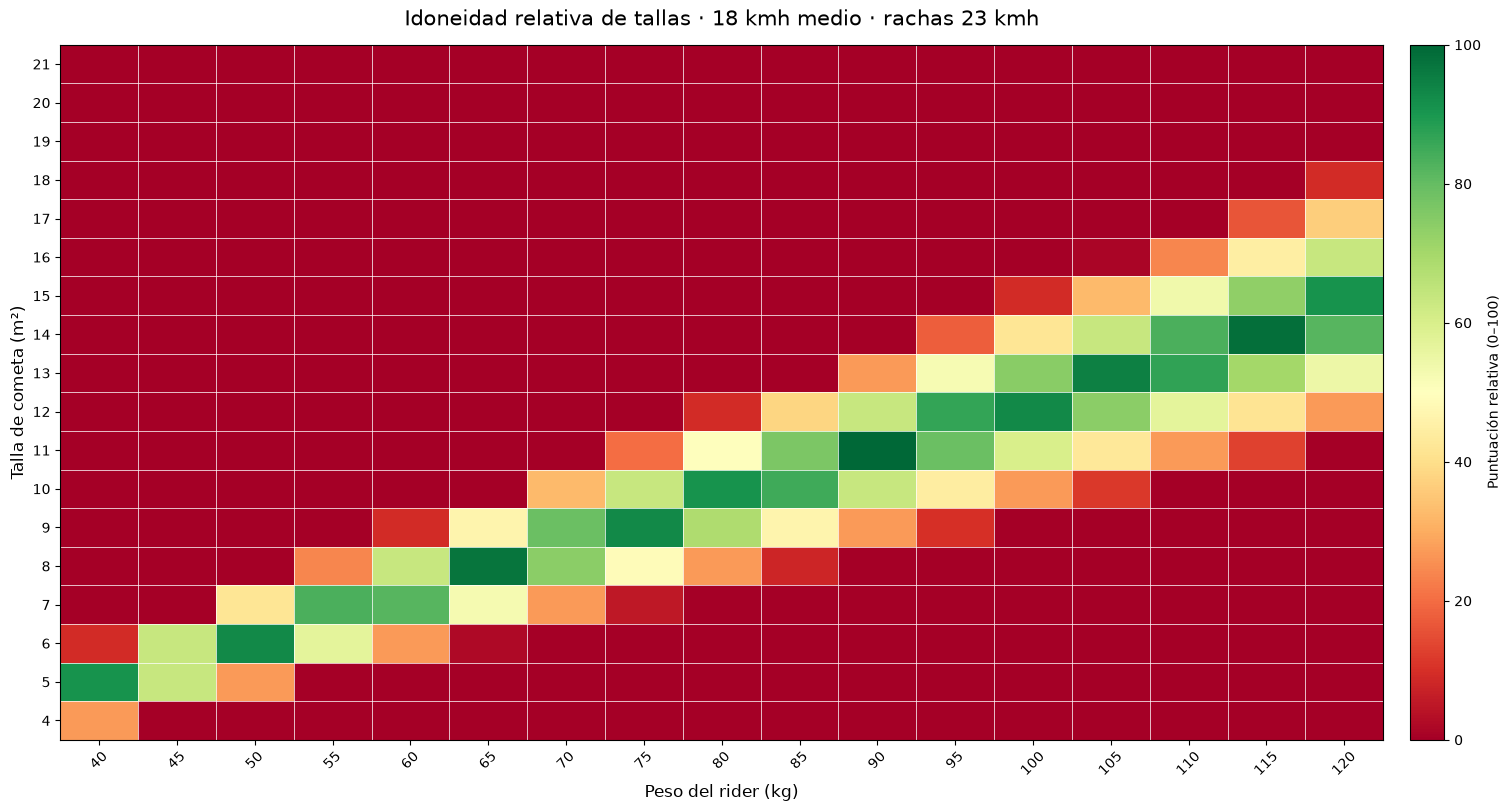

In [13]:
scores = build_scores(WIND_MEAN_KMH)

fig, ax = plt.subplots(figsize=(15, 8), constrained_layout=True)
image = ax.imshow(
    scores,
    origin="lower",
    aspect="auto",
    interpolation="nearest",
    extent=[
        weights_kg[0] - WEIGHT_STEP_KG / 2,
        weights_kg[-1] + WEIGHT_STEP_KG / 2,
        kite_sizes_m2[0] - 0.5,
        kite_sizes_m2[-1] + 0.5,
    ],
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
)

wind_label = f"{WIND_MEAN_KMH:g} kmh medio"
if WIND_GUSTS_KMH is not None:
    wind_label += f" · rachas {WIND_GUSTS_KMH:g} kmh"
ax.set_title(f"Idoneidad relativa de tallas · {wind_label}", fontsize=15, pad=14)
ax.set_xlabel("Peso del rider (kg)", fontsize=12)
ax.set_ylabel("Talla de cometa (m²)", fontsize=12)
ax.set_xticks(weights_kg)
ax.set_yticks(kite_sizes_m2)
ax.tick_params(axis="x", labelrotation=45)
ax.set_xticks(np.arange(weights_kg[0] - 2.5, weights_kg[-1] + 2.6, 5), minor=True)
ax.set_yticks(np.arange(kite_sizes_m2[0] - 0.5, kite_sizes_m2[-1] + 0.6, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.7, alpha=0.75)
ax.tick_params(which="minor", bottom=False, left=False)

cbar = fig.colorbar(image, ax=ax, pad=0.02)
cbar.set_label("Puntuación relativa (0–100)")
plt.show()

## 3. Diagnóstico por peso

Esta tabla permite ver si la talla calculada cae dentro del rango visible. Si la talla ideal está por debajo de 4 m² o por encima de 21 m², la matriz no contiene esa talla; la mejor celda disponible no debe confundirse con una talla adecuada.

In [14]:
rows = []
for weight in weights_kg:
    ideal = ideal_kite_size(float(weight), WIND_MEAN_KMH)
    col = int(np.where(weights_kg == weight)[0][0])
    best_row = int(np.argmax(scores[:, col]))
    best_size = int(kite_sizes_m2[best_row])
    rows.append(
        {
            "weight": int(weight),
            "ideal": ideal,
            "best_size": best_size,
            "score": float(scores[best_row, col]),
            "out_of_range": ideal < KITE_SIZE_MIN_M2 or ideal > KITE_SIZE_MAX_M2,
        }
    )

print(
    f"{'Peso':>6} {'Teórica':>10} {'Mejor visible':>15} {'Score':>9} {'Fuera de rango':>16}"
)
for row in rows:
    print(
        f"{row['weight']:>6} kg "
        f"{row['ideal']:>8.2f} m² "
        f"{row['best_size']:>12} m² "
        f"{row['score']:>7.1f}/100 "
        f"{('Sí' if row['out_of_range'] else 'No'):>16}"
    )

  Peso    Teórica   Mejor visible     Score   Fuera de rango
    40 kg     4.89 m²            5 m²    90.9/100               No
    45 kg     5.50 m²            6 m²    63.6/100               No
    50 kg     6.11 m²            6 m²    92.7/100               No
    55 kg     6.72 m²            7 m²    83.5/100               No
    60 kg     7.33 m²            7 m²    81.8/100               No
    65 kg     7.94 m²            8 m²    97.2/100               No
    70 kg     8.56 m²            9 m²    79.2/100               No
    75 kg     9.17 m²            9 m²    92.7/100               No
    80 kg     9.78 m²           10 m²    90.9/100               No
    85 kg    10.39 m²           10 m²    85.0/100               No
    90 kg    11.00 m²           11 m²   100.0/100               No
    95 kg    11.61 m²           12 m²    86.6/100               No
   100 kg    12.22 m²           12 m²    92.7/100               No
   105 kg    12.83 m²           13 m²    94.8/100               No
 

## 4. Comprobación puntual de la tolerancia

La puntuación actual cae linealmente hasta cero cuando la diferencia con la talla teórica alcanza el 25 % (constante `SIZE_TOLERANCE_RATIO` del servicio) de esta. Esto hace que el mapa parezca más preciso de lo que la regla de base realmente es: el 25 % (constante `SIZE_TOLERANCE_RATIO` del servicio) es una elección de diseño provisional, no un umbral validado por un fabricante.

In [15]:
example_weights = [60, 75, 90, 105]
print(f"{'Peso':>6} {'Viento':>10} {'Talla teórica':>16} {'Intervalo score > 0':>24}")
for weight in example_weights:
    ideal = ideal_kite_size(weight, WIND_MEAN_KMH)
    tolerance = ideal * SIZE_TOLERANCE_RATIO
    interval = f"{ideal - tolerance:.1f}–{ideal + tolerance:.1f} m²"
    print(f"{weight:>6} kg {WIND_MEAN_KMH:>8.1f} kmh {ideal:>13.2f} m² {interval:>24}")

  Peso     Viento    Talla teórica      Intervalo score > 0
    60 kg     18.0 kmh          7.33 m²               5.5–9.2 m²
    75 kg     18.0 kmh          9.17 m²              6.9–11.5 m²
    90 kg     18.0 kmh         11.00 m²              8.3–13.8 m²
   105 kg     18.0 kmh         12.83 m²              9.6–16.0 m²


## 5. Referencias para la siguiente iteración

- [DUOTONE: cometas y guía general de tallas](https://www.duotonesports.com/es/kiteboarding/cometas): presenta recomendaciones generales por peso y viento, pero son orientativas.
- [DUOTONE Neo Concept Blue 2026](https://www.duotonesports.com/es/products/duotone-neo-concept-blue-2026-44260-3034): publica rangos de viento por talla para un modelo concreto.
- [WindSensei: calculadora y tabla por peso/viento](https://windsensei.com/kite-size-calculator): documenta la fórmula de regla práctica `peso × 2.2 / nudos` y sus limitaciones.
- [Kitewind: explicación de la fórmula](https://kitewind.nl/en/uitleg/what-size-kite): señala que la regla es una aproximación práctica y no una relación física exacta.

### Decisiones recomendadas antes de convertirlo en recomendación de producto

1. Definir si el producto asume twin-tip freeride y un nivel de experiencia concreto.
2. Elegir uno o varios modelos de referencia; comparar con sus rangos oficiales, no mezclar modelos como si fueran equivalentes.
3. Decidir cómo representar la incertidumbre: una zona de tallas candidatas es más honesta que una puntuación que parezca una probabilidad.
4. Tratar rachas y viento medio como datos separados hasta disponer de una regla calibrada. No ajustar automáticamente la talla con un multiplicador arbitrario.
5. Mantener la evaluación general de las condiciones separada de la matriz de tallas.